In [ ]:
import hashlib
import io
import json
import tempfile
from pathlib import Path

import exchange_calendars as xcals
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import requests
import seaborn as sns
import yfinance as yf
from arch.unitroot import ADF
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import het_arch

# 1. Сбор данных

Мы решили изучать на этапе EDA "самые ликвидные" 10 компаний с 2010-2025. Чтобы не создать bias в данных, возьмём 10 компаний с самой высокой оценкой ежедневного денежного оборота (dollar volume) в среднем с 1 по 31 декабря 2009. Финансовые данные соберём с yfinance.

Данные сохраняются локально в `data/raw/`: при повторном выполнении ячеек читаем готовые файлы. Кэш учитывает параметры запроса, а для котировок — также версию yfinance. Для принудительного обновления установите `REFRESH_DATA = True` в первой ячейке; после обновления верните `False`. Файлы данных не включаются в Git.

## 1.1. Выбор компаний

Сперва нужно понять, среди каких компаний можно найти те, что имеют самую высокую капитализацию. Что очень приятно, на Википедии есть статья со всеми компаниями в S&P500 с версией на 31 декабря 2009: https://en.wikipedia.org/w/index.php?title=List_of_S%26P_500_companies&oldid=335120317. Нам лишь остается достать оттуда список тикеров и найти топ 10 по dollar volume.

In [ ]:
PROJECT_ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
                    if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
DATA_DIR = PROJECT_ROOT / "data" / "raw"
DATA_DIR.mkdir(parents=True, exist_ok=True)
REFRESH_DATA = False


def load_or_download(dataset, parameters, download):
    """Читаем локальный снимок или скачиваем и сохраняем непустую таблицу."""
    key = hashlib.sha256(json.dumps(parameters, sort_keys=True).encode()).hexdigest()[:16]
    cache_path = DATA_DIR / f"{dataset}-{key}.pkl"
    if cache_path.exists() and not REFRESH_DATA:
        print(f"Из кэша: {cache_path.name}")
        return pd.read_pickle(cache_path)

    frame = download()
    if not isinstance(frame, pd.DataFrame) or frame.dropna(how="all").empty:
        raise RuntimeError(f"Не удалось загрузить {dataset}: пустые данные не сохраняем")

    # Заменяем снимок только после успешной записи целого файла.
    with tempfile.NamedTemporaryFile(dir=DATA_DIR, suffix=".tmp", delete=False) as temporary:
        temporary_path = Path(temporary.name)
    try:
        frame.to_pickle(temporary_path)
        temporary_path.replace(cache_path)
    finally:
        temporary_path.unlink(missing_ok=True)
    print(f"Сохранено: {cache_path.name}")
    return frame


WIKI_OLDID = 335120317  # версия на 31.12.2009
UA = {"User-Agent": "Nikita Kliuchnikov niklyuchnikov@edu.hse.ru"}  # меняйте на свой!
wiki_url = "https://en.wikipedia.org/w/index.php"
wiki_params = {"title": "List_of_S&P_500_companies", "oldid": WIKI_OLDID}


def download_constituents():
    response = requests.get(wiki_url, params=wiki_params, headers=UA, timeout=30)
    response.raise_for_status()
    return pd.read_html(io.StringIO(response.text))[0]


wiki = load_or_download("sp500", {"url": wiki_url, **wiki_params}, download_constituents)
sym_col = next(c for c in wiki.columns if "symbol" in str(c).lower() or "ticker" in str(c).lower())

# заменяем тикеры на формат yfinance:
tickers = sorted(wiki[sym_col].astype(str).str.strip().str.replace(".", "-", regex=False).unique().dropna())
print(len(tickers), "компаний:", tickers[:5], "и так далее")

Из кэша: sp500-36f0a43075b4a2e8.pkl
500 компаний: ['A', 'AA', 'AAPL', 'ABC', 'ABT'] и так далее


Все версии страницы можно посмотреть здесь: https://en.wikipedia.org/w/index.php?title=List_of_S%26P_500_companies&action=history&dir=prev&limit=500.

Идея: в дальнейшем брать списки акций оттуда!

Теперь посчитаем dollar volume: берём цены закрытия (adjusted) и объём торгов (тоже adjusted). Утверждается, что если взять оба adjusted, то возможные корректировки правильно взаимо-вычтутся, чтобы правильно считалась оценка dollar volume. TODO: убедиться в справедливости этого.

Важный нюанс: это лишь оценка – настоящий dollar volume считался бы по цене каждой сделки!

In [ ]:
liquidity_params = {
    "tickers": tickers,
    "start": "2009-12-01",
    "end": "2010-01-01",
    "auto_adjust": True,
}
prices_2009 = load_or_download(
    "liquidity",
    {
        "yfinance_version": yf.__version__,
        **liquidity_params
    },
    lambda: yf.download(**liquidity_params),
)

dollar_volume = prices_2009['Close'] * prices_2009['Volume']
adv = dollar_volume.mean().dropna()
top_tickers = adv.sort_values(ascending=False).head(10).index.tolist()
top_tickers

Из кэша: liquidity-7b6dc94c0738faf6.pkl


['AAPL', 'BAC', 'C', 'AMZN', 'GOOG', 'XOM', 'WFC', 'GS', 'MSFT', 'JPM']

## 1.2. Загрузка OHLCV данных

Для сборки свечей выбранных компаний используем снова yfinance.

Важно: это сырые данные без корректировок. Хочется сперва посмотреть на них.

In [ ]:
ohlcv_params = {
    "tickers": top_tickers,
    "start": "2010-01-01",
    "end": "2026-01-01",
    "auto_adjust": False,
}
ohlcv_top_not_adj = load_or_download(
    "ohlcv",
    {
        "yfinance_version": yf.__version__,
        **ohlcv_params
    },
    lambda: yf.download(**ohlcv_params),
)

Из кэша: ohlcv-14c665cf81c3bcf4.pkl


Посмотрим на график сырой цены:

In [5]:
assert ohlcv_top_not_adj is not None
close_raw = ohlcv_top_not_adj.Close[top_tickers]  # в порядке убывания по ликвидности

fig = px.line(close_raw, title="Динамика Цен, Top-Market-Cap Акции на начало 2010 года")
fig.update_layout(xaxis={'title': {'text': "Дата"}}, yaxis={'title': {'text': "Цена закрытия"}})
fig.show()

Отнормируем так, чтобы все цены начинались в 1 (получаются кумулятивные доходности), а также возьмём логарифмическую шкалу.

In [6]:
fig = px.line(close_raw / close_raw.iloc[0],
              title="Динамика Цен, Top-Market-Cap Акции на начало 2010 года, Нормировка по начальной цене",
              log_y=True)
fig.update_layout(
    xaxis={'title': {
        'text': "Дата"
    }},
    yaxis={
        'title': {
            'text': "Кумулятивная доходность"
        },
        "showexponent": 'all',  # TODO: пофиксить шкалу по y - это не помогло
        "exponentformat": 'e'
    },
)
fig.show()

Можем посмотреть на свечи (candlestick chart) для каждой акции. Вот, например, последние 100 наблюдений по Apple в датасете:

In [7]:
assert ohlcv_top_not_adj is not None
aapl_raw_sample = ohlcv_top_not_adj[:, "AAPL"].iloc[-100:]

fig = go.Figure(data=[
    go.Candlestick(
        x=aapl_raw_sample.index,
        open=aapl_raw_sample.Open,
        high=aapl_raw_sample.High,
        low=aapl_raw_sample.Low,
        close=aapl_raw_sample.Close,
    )
])
fig.update_layout(
    title="OHLCV для AAPL – последние 100 наблюдений",
    xaxis_rangeslider_visible=False,
    xaxis={'title': {
        'text': "Дата"
    }},
    yaxis={'title': {
        'text': "Цена"
    }},
)
fig.show()

# 2. Покрытие данных выбранных компаний

Проверим, есть ли данные по нашей десятке за все торговые дни 2010-2025 годов. Одно наблюдение соответствует одной торговой сессии одной акции.

Даты сравним с календарём NYSE (`XNYS`). В нём учтены праздники и внеплановые закрытия биржи, поэтому такие дни не попадут в пропуски. Для выбранных американских акций используем его как общий календарь дневных торгов. [Источник календаря](https://github.com/gerrymanoim/exchange_calendars).

In [ ]:
quote_fields = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
price_fields = quote_fields[:-1]
keys = ["Date", "Ticker"]
period_start = pd.Timestamp(ohlcv_params["start"])
period_end = pd.Timestamp(ohlcv_params["end"]) - pd.Timedelta(days=1)
calendar = xcals.get_calendar("XNYS", start=period_start, end=period_end)
trading_days = calendar.sessions  # календарь уже ограничен period_start и period_end

# Переходим от широких столбцов (признак, тикер) к строкам (дата, тикер).
quotes_raw = (
    ohlcv_top_not_adj.rename_axis("Date").stack("Ticker").reset_index()[keys +
                                                                        quote_fields].sort_values(keys).reset_index(
                                                                            drop=True))
quotes = quotes_raw.drop_duplicates().copy()
exact_duplicates = len(quotes_raw) - len(quotes)
conflicting_keys = quotes.duplicated(keys, keep=False)
expected_grid = pd.MultiIndex.from_product([trading_days, top_tickers], names=keys)
aligned_quotes = (quotes.loc[~conflicting_keys].set_index(keys)[quote_fields].reindex(expected_grid))
print(f"Период: {period_start.date()} - {period_end.date()}")
print(f"Компаний: {len(top_tickers)}; торговых сессий: {len(trading_days):,}")
print(f"Строк в выгрузке: {len(quotes_raw):,}; ожидается: {len(expected_grid):,}")

Период: 2010-01-01 - 2025-12-31
Компаний: 10; торговых сессий: 4,024
Строк в выгрузке: 40,240; ожидается: 40,240


In [9]:
quotes.head()

Price,Date,Ticker,Open,High,Low,Close,Adj Close,Volume
0,2010-01-04,AAPL,7.622500,7.660714,7.585000,7.643214,6.400961,493729600
1,2010-01-04,AMZN,6.812500,6.830500,6.657000,6.695000,6.695000,151998000
2,2010-01-04,BAC,15.240000,15.750000,15.120000,15.690000,11.977125,180845200
3,2010-01-04,C,33.599998,34.099998,33.400002,34.000000,24.716986,40679350
4,2010-01-04,GOOG,15.615220,15.678981,15.547723,15.610239,15.463772,78541293


In [ ]:
complete_candles = aligned_quotes.notna().all(axis=1).unstack("Ticker")
coverage = complete_candles.sum().to_frame("Полных свечей")
coverage["Ожидается"] = len(trading_days)
coverage["Неполных или отсутствующих"] = coverage["Ожидается"] - coverage["Полных свечей"]
coverage["Покрытие, %"] = 100 * coverage["Полных свечей"] / coverage["Ожидается"]

available_dates = (aligned_quotes.dropna().reset_index().groupby("Ticker")["Date"].agg(
    ["min", "max"]).rename(columns={
        "min": "Первая свеча",
        "max": "Последняя свеча"
    }))
coverage = coverage.join(available_dates).reindex(top_tickers)
display(
    coverage.style.format({
        "Покрытие, %": "{:.2f}",
        "Первая свеча": "{:%Y-%m-%d}",
        "Последняя свеча": "{:%Y-%m-%d}",
    },
                          na_rep="нет данных"))

unexpected_dates = pd.DatetimeIndex(quotes["Date"].unique()).difference(trading_days)
print(f"Дат вне выбранного торгового календаря: {len(unexpected_dates)}")
print(f"Точных повторов строк: {exact_duplicates}; строк с конфликтом ключа: {conflicting_keys.sum()}")

,Полных свечей,Ожидается,Неполных или отсутствующих,"Покрытие, %",Первая свеча,Последняя свеча
Ticker,,,,,,
AAPL,4024,4024,0,100.00,2010-01-04,2025-12-31
BAC,4024,4024,0,100.00,2010-01-04,2025-12-31
C,4024,4024,0,100.00,2010-01-04,2025-12-31
AMZN,4024,4024,0,100.00,2010-01-04,2025-12-31
GOOG,4024,4024,0,100.00,2010-01-04,2025-12-31
XOM,4024,4024,0,100.00,2010-01-04,2025-12-31
WFC,4024,4024,0,100.00,2010-01-04,2025-12-31
GS,4024,4024,0,100.00,2010-01-04,2025-12-31
MSFT,4024,4024,0,100.00,2010-01-04,2025-12-31


Дат вне выбранного торгового календаря: 0
Точных повторов строк: 0; строк с конфликтом ключа: 0


У всех десяти акций есть полные свечи за 4024 торговые сессии: с 4 января 2010 года по 31 декабря 2025 года. Для каждой компании покрытие составляет 100%, всего получилось 40 240 строк с парами дата и тикер. Пропущенных свечей, лишних дат, повторов строк и разных записей для одной пары дата и тикер не нашли.

# 3. Аудит качества данных

Проверим шесть числовых полей OHLCV: пропуски, типы данных, допустимость цен и объёмов, границы свечей. Дата и тикер служат для поиска записей и в долю пропусков числовых полей не входят.

Работаем с копией данных. Исходную выгрузку `ohlcv_top_not_adj` и файлы в `data/raw/` сохраняем, а таблицу после проверок назовём `quotes_clean`.

In [11]:
missing_report = pd.DataFrame({
    "Тип в исходной таблице": quotes_raw[quote_fields].dtypes.astype(str),
    "Непустых значений": aligned_quotes[quote_fields].notna().sum(),
    "Пропусков": aligned_quotes[quote_fields].isna().sum(),
    "Доля пропусков, %": aligned_quotes[quote_fields].isna().mean() * 100,
})
display(missing_report.style.format({"Доля пропусков, %": "{:.3f}"}))

missing_cells = int(aligned_quotes[quote_fields].isna().sum().sum())
missing_share = missing_cells / aligned_quotes[quote_fields].size
print(f"Всего пропусков: {missing_cells:,} из {aligned_quotes[quote_fields].size:,} значений ({missing_share:.3%})")

,Тип в исходной таблице,Непустых значений,Пропусков,"Доля пропусков, %"
Price,,,,
Open,float64,40240,0,0.000
High,float64,40240,0,0.000
Low,float64,40240,0,0.000
Close,float64,40240,0,0.000
Adj Close,float64,40240,0,0.000
Volume,int64,40240,0,0.000


Всего пропусков: 0 из 241,440 значений (0.000%)


In [ ]:
def find_quality_issues(frame, sessions):
    fields = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
    values = frame[fields].apply(pd.to_numeric, errors="coerce")
    prices = values[fields[:-1]]
    volume = values["Volume"]
    ohlc = values[["Open", "High", "Low", "Close"]]
    complete_ohlc = ohlc.notna().all(axis=1) & np.isfinite(ohlc).all(axis=1)
    tolerance = 1e-8
    inconsistent_ohlc = ((ohlc["High"] + tolerance < ohlc[["Open", "Close"]].max(axis=1))
                         | (ohlc["Low"] - tolerance > ohlc[["Open", "Close"]].min(axis=1))
                         | (ohlc["Low"] > ohlc["High"] + tolerance))
    return pd.DataFrame(
        {
            "Пропущенное значение": frame[fields].isna().any(axis=1),
            "Нечисловое значение": (frame[fields].notna() & values.isna()).any(axis=1),
            "Бесконечное значение": np.isinf(values).any(axis=1),
            "Неположительная цена": prices.le(0).any(axis=1),
            "Отрицательный объём": volume.lt(0),
            "Дробный объём": np.isfinite(volume) & volume.mod(1).abs().gt(tolerance),
            "Нарушение OHLC": complete_ohlc & inconsistent_ohlc,
            "Конфликт даты и тикера": frame.duplicated(["Date", "Ticker"], keep=False),
            "Дата вне календаря": ~frame["Date"].isin(sessions),
        },
        index=frame.index)

In [13]:
quality_issues = find_quality_issues(quotes, trading_days)
invalid_rows = quality_issues.any(axis=1)
zero_volume = quotes["Volume"].eq(0)

quality_report = quality_issues.sum()
quality_report.loc["Нулевой объём"] = zero_volume.sum()
quality_report = quality_report.to_frame("Количество строк")
quality_report["Доля строк, %"] = quality_report["Количество строк"] / len(quotes) * 100
display(quality_report.style.format({"Доля строк, %": "{:.3f}"}))

if invalid_rows.any():
    display(quotes.loc[invalid_rows, keys + quote_fields].head(10))

,Количество строк,"Доля строк, %"
Пропущенное значение,0,0.000
Нечисловое значение,0,0.000
Бесконечное значение,0,0.000
Неположительная цена,0,0.000
Отрицательный объём,0,0.000
Дробный объём,0,0.000
Нарушение OHLC,0,0.000
Конфликт даты и тикера,0,0.000
Дата вне календаря,0,0.000
Нулевой объём,0,0.000


Ошибок по проверенным правилам не нашли: цены и объёмы допустимы, границы свечей согласованы, конфликтов по дате и тикеру нет. Строк с нулевым объёмом тоже нет.

## 3.1. Необычные движения цены

Большое изменение цены за день может быть и ошибкой источника, и реальным рыночным событием. Сначала найдём такие дни, чтобы посмотреть на них отдельно.

Доходность считаем по `Adj Close` отдельно для каждой акции и сравниваем с её медианой за весь период. Разброс оцениваем через MAD: медианное абсолютное отклонение от этой медианы.

Отмечаем дни, для которых `|0.6745 × (r - median) / MAD| > 3.5`. Коэффициент и порог взяты из методики NIST, по нашим данным их не подбирали. Это правило помогает выбрать наблюдения для проверки, но само по себе не доказывает ошибку в котировке. [Описание метода](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm).

In [ ]:
valid_adj_close = (quotes.loc[~invalid_rows].set_index(keys)["Adj Close"].reindex(expected_grid))
# Полная сетка дат сохраняет пропуски: pct_change не перескакивает через них.
daily_returns = valid_adj_close.groupby(level="Ticker").pct_change(fill_method=None)
median_return = daily_returns.groupby(level="Ticker").transform("median")
absolute_deviation = (daily_returns - median_return).abs()
mad = absolute_deviation.groupby(level="Ticker").transform("median")
modified_z = 0.6745 * (daily_returns - median_return) / mad.replace(0, np.nan)
unusual_move = modified_z.abs().gt(3.5)

outlier_report = pd.DataFrame({
    "Дней с рассчитанной доходностью": daily_returns.groupby(level="Ticker").count(),
    "Отмечено дней": unusual_move.groupby(level="Ticker").sum(),
}).reindex(top_tickers)
outlier_report.loc["Всего"] = outlier_report.sum()
outlier_report["Доля, %"] = (outlier_report["Отмечено дней"] / outlier_report["Дней с рассчитанной доходностью"] * 100)
display(outlier_report.style.format({"Доля, %": "{:.2f}"}))

,Дней с рассчитанной доходностью,Отмечено дней,"Доля, %"
Ticker,,,
AAPL,4023,97,2.41
BAC,4023,110,2.73
C,4023,125,3.11
AMZN,4023,93,2.31
GOOG,4023,112,2.78
XOM,4023,105,2.61
WFC,4023,129,3.21
GS,4023,69,1.72
MSFT,4023,83,2.06


In [ ]:
unusual_moves = pd.DataFrame({
    "Дневная доходность": daily_returns,
    "MAD-оценка": modified_z,
}).loc[unusual_move].reset_index()

largest_moves = unusual_moves.sort_values("Дневная доходность", key=abs, ascending=False).head(10)
display(largest_moves.style.format({
    "Date": "{:%Y-%m-%d}",
    "Дневная доходность": "{:+.2%}",
    "MAD-оценка": "{:+.2f}",
}))

,Date,Ticker,Дневная доходность,MAD-оценка
80,2011-08-08,BAC,-20.32%,-13.52
527,2020-03-16,C,-19.30%,-13.25
524,2020-03-13,JPM,+18.01%,+14.53
518,2020-03-13,C,+17.98%,+12.29
517,2020-03-13,BAC,+17.80%,+11.78
522,2020-03-13,GS,+17.58%,+12.77
89,2011-08-09,BAC,+16.74%,+11.08
81,2011-08-08,C,-16.42%,-11.28
560,2020-03-24,BAC,+16.32%,+10.80
485,2020-03-09,C,-16.17%,-11.11


In [ ]:
quotes_clean = quotes.loc[~invalid_rows, keys + quote_fields].copy()
cleaning_report = pd.Series(
    {
        "Строк в исходной выгрузке": len(quotes_raw),
        "Удалено точных повторов": exact_duplicates,
        "Отложено строк с ошибками или пропусками": int(invalid_rows.sum()),
        "Строк в рабочей таблице quotes_clean": len(quotes_clean),
        "Отмечено необычных движений (сохраняем)": len(unusual_moves),
    },
    name="Количество")
display(cleaning_report.to_frame())

,Количество
Строк в исходной выгрузке,40240
Удалено точных повторов,0
Отложено строк с ошибками или пропусками,0
Строк в рабочей таблице quotes_clean,40240
Отмечено необычных движений (сохраняем),1032


В шести полях OHLCV проверили 241 440 значений. Пропусков нет. Даты совпадают с торговым календарём; выходные и биржевые праздники не считаем пропущенными наблюдениями.

Проверки цен, объёмов, границ свечей и дубликатов проблем не выявили. Ничего удалять или заполнять не пришлось: в `quotes_clean` остались все 40 240 строк.

По MAD отмечены 1033 дневных изменения, или 2,57% из 40 230 рассчитанных доходностей. Среди крупнейших движений есть BAC 8 августа 2011 года (-20,32%) и JPM 13 марта 2020 года (+18,01%). Причины этих скачков мы пока не выясняли.

Дальше работаем с `quotes_clean`. Резкие движения сохраняем: одного большого изменения цены недостаточно, чтобы удалить наблюдение.

# 4. Описательные статистики и распределения

Посмотрим на значения признаков в `quotes_clean`, затем сравним дневные доходности и объёмы разных акций.

In [ ]:
descriptive_stats = quotes_clean.drop(columns="Date").describe(include="all").T
display(
    descriptive_stats.style.format(
        {
            "count": "{:.0f}",
            "unique": "{:.0f}",
            "freq": "{:.0f}"
        },
        precision=2,
        thousands=" ",
        na_rep="-",
    ))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Price,,,,,,,,,,,
Ticker,40240,10,AAPL,4024,-,-,-,-,-,-,-
Open,40240,-,-,-,96.33,101.66,5.11,33.67,58.36,120.78,913.75
High,40240,-,-,-,97.31,102.70,5.22,34.05,58.89,121.94,919.10
Low,40240,-,-,-,95.34,100.64,4.92,33.27,57.87,119.45,905.31
Close,40240,-,-,-,96.35,101.71,4.99,33.70,58.37,120.58,911.03
Adj Close,40240,-,-,-,85.95,98.49,3.84,27.43,47.77,111.66,897.89
Volume,40240,-,-,-,56 829 112.51,97 434 082.76,158 434.00,14 448 175.00,27 310 650.00,59 511 150.00,1 880 998 000.00


У каждой компании по 4024 наблюдения. Знак `-` в таблице означает, что статистика не подходит для этого типа данных: например, среднее для тикера не рассчитывается.

Средний дневной объём торгов составляет 56,83 млн акций, медианный 27,31 млн. Среднее заметно выше медианы, поэтому для обычного дня медиана здесь показательнее. Таблица объединяет разные компании и годы; ниже сравним акции отдельно.

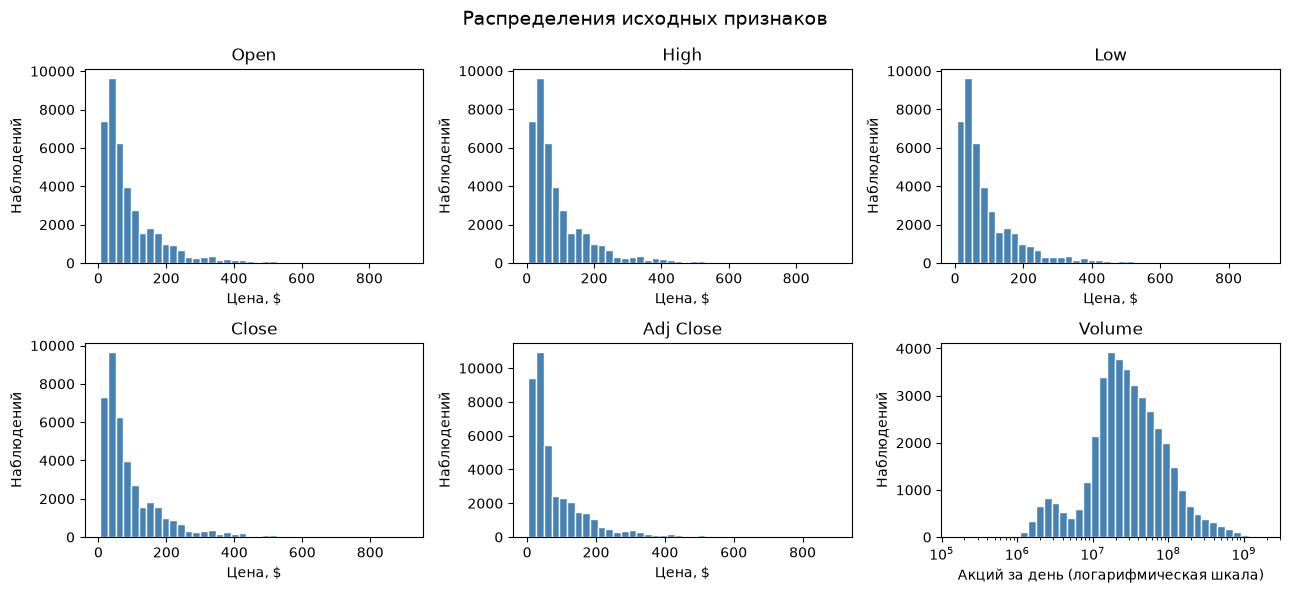

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, field in zip(axes.flat, quote_fields):
    values = quotes_clean[field]
    if field == "Volume":
        values = values[values > 0]
        bins = np.geomspace(values.min(), values.max(), 40)
        ax.hist(values, bins=bins, color="steelblue", edgecolor="white")
        ax.set_xscale("log")
        ax.set_xlabel("Акций за день (логарифмическая шкала)")
    else:
        ax.hist(values, bins=40, color="steelblue", edgecolor="white")
        ax.set_xlabel("Цена, $")
    ax.set_title(field)
    ax.set_ylabel("Наблюдений")
fig.suptitle("Распределения исходных признаков", fontsize=14)
fig.tight_layout()
plt.show()

In [ ]:
distribution_data = quotes_clean.sort_values(["Ticker", "Date"]).copy()
distribution_data["Return_pct"] = (distribution_data.groupby("Ticker")["Adj Close"].pct_change(fill_method=None) * 100)
returns_by_ticker = distribution_data.groupby("Ticker")["Return_pct"]
ticker_stats = returns_by_ticker.describe(percentiles=[0.01, 0.5, 0.99])[["mean", "50%", "std", "1%", "99%"]]
ticker_stats["median_volume_mln"] = distribution_data.groupby("Ticker")["Volume"].median() / 1e6
ticker_stats = ticker_stats.rename(
    columns={
        "mean": "Средняя доходность, %",
        "50%": "Медиана доходности, %",
        "std": "Стандартное отклонение, %",
        "1%": "Квантиль 1%, %",
        "99%": "Квантиль 99%, %",
        "median_volume_mln": "Медианный объём, млн акций",
    })
display(ticker_stats.reindex(top_tickers).style.format(precision=2))

,"Средняя доходность, %","Медиана доходности, %","Стандартное отклонение, %","Квантиль 1%, %","Квантиль 99%, %","Медианный объём, млн акций"
Ticker,,,,,,
AAPL,0.11,0.10,1.77,-4.67,4.90,130.78
BAC,0.06,0.05,2.09,-5.63,6.00,66.84
C,0.06,0.05,2.13,-5.63,6.06,19.22
AMZN,0.11,0.09,2.07,-5.50,5.84,67.75
GOOG,0.09,0.08,1.74,-4.77,4.68,32.38
XOM,0.04,0.02,1.57,-4.34,4.25,15.04
WFC,0.06,0.04,1.88,-5.25,5.53,19.91
GS,0.06,0.06,1.81,-4.61,4.45,2.90
MSFT,0.09,0.07,1.61,-4.11,4.23,29.39


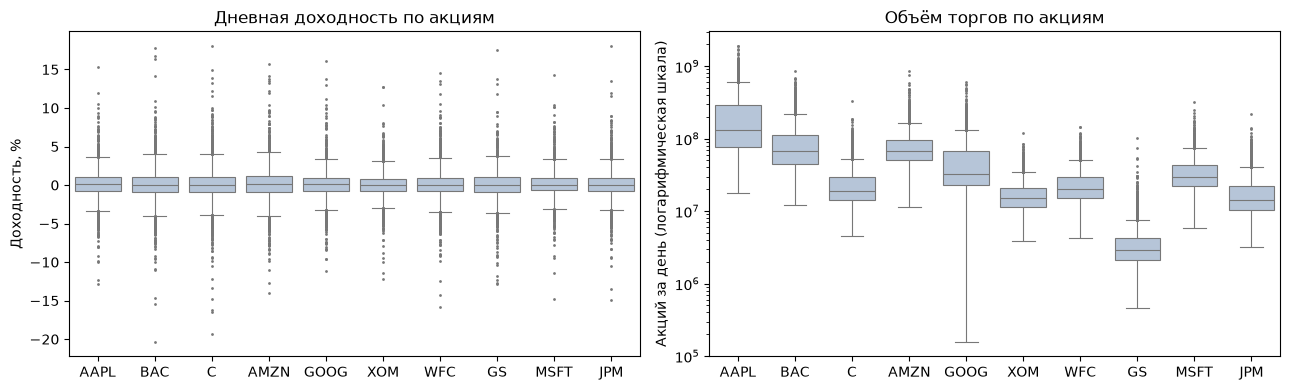

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(
    data=distribution_data,
    x="Ticker",
    y="Return_pct",
    order=top_tickers,
    color="lightsteelblue",
    fliersize=1,
    linewidth=0.8,
    ax=axes[0],
)
axes[0].set(title="Дневная доходность по акциям", xlabel="", ylabel="Доходность, %")
sns.boxplot(
    data=distribution_data,
    x="Ticker",
    y="Volume",
    order=top_tickers,
    color="lightsteelblue",
    fliersize=1,
    linewidth=0.8,
    ax=axes[1],
)
axes[1].set_yscale("log")
axes[1].set(title="Объём торгов по акциям", xlabel="", ylabel="Акций за день (логарифмическая шкала)")
fig.tight_layout()
plt.show()

У C и BAC самый большой разброс дневной доходности: стандартное отклонение составляет 2,13% и 2,09%. У XOM и MSFT оно меньше: 1,57% и 1,61%. Медианные объёмы тоже различаются: у AAPL 130,78 млн акций в день, у GS 2,90 млн.

Для объёма используем логарифмическую шкалу, чтобы были видны и обычные дни, и дни с очень большим объёмом торгов. Компании дальше будем сравнивать по доходностям и их разбросу. Разный масштаб объёмов учтём при подготовке признаков.

Boxplot отмечает точки за усами по правилу межквартильного размаха (IQR), а в предыдущем разделе мы использовали MAD. Правила разные; эти отметки не означают, что в данных ошибка. Ничего на графиках не обрезали.

# 5. Автокорреляция доходностей

Для каждой акции строим ряд скорректированных цен `Adj Close` на общей сетке `trading_days`, затем считаем простые дневные доходности.

Сравним знаковые доходности и их модули. Первая оценка показывает линейную зависимость доходностей; автокорреляция модулей помогает увидеть устойчивость масштаба колебаний.

In [ ]:
# Общая календарная сетка удерживает пропущенные торговые сессии на месте.
adj_close = (quotes_clean.pivot(index="Date", columns="Ticker",
                                values="Adj Close").reindex(index=trading_days, columns=top_tickers).sort_index())
returns = adj_close.pct_change(fill_method=None)
abs_returns = returns.abs()
acf_lags = range(1, 31)


# Учитываем только пары, где оба значения ряда доступны.
def autocorrelation_summary(series):
    rows = []
    for lag in acf_lags:
        pairs = pd.concat([series, series.shift(lag)], axis=1).dropna()
        rows.append({
            "Лаг (торговых сессий)": lag,
            "Автокорреляция": pairs.iloc[:, 0].corr(pairs.iloc[:, 1]),
            "Число пар N": len(pairs),
        })
    return pd.DataFrame(rows).set_index("Лаг (торговых сессий)")


acf_returns = {ticker: autocorrelation_summary(returns[ticker]) for ticker in top_tickers}
acf_abs_returns = {ticker: autocorrelation_summary(abs_returns[ticker]) for ticker in top_tickers}

selected_lags = [1, 5, 20]


def selected_lag_table(results):
    rows = []
    for ticker, summary in results.items():
        for lag in selected_lags:
            rows.append({
                "Тикер": ticker,
                "Лаг": lag,
                "Автокорреляция": summary.loc[lag, "Автокорреляция"],
                "Число пар N": int(summary.loc[lag, "Число пар N"]),
            })
    return pd.DataFrame(rows).pivot(index="Тикер", columns="Лаг", values=["Автокорреляция", "Число пар N"])


print("Знаковые дневные доходности")
display(selected_lag_table(acf_returns).round(3))
print("Модули дневных доходностей")
display(selected_lag_table(acf_abs_returns).round(3))

Знаковые дневные доходности


Автокорреляция               Число пар N                
Лаг               1      5      20          1       5       20
Тикер                                                         
AAPL          -0.034 -0.002  0.003      4022.0  4018.0  4003.0
AMZN          -0.023  0.005 -0.004      4022.0  4018.0  4003.0
BAC           -0.050 -0.043  0.028      4022.0  4018.0  4003.0
C             -0.049 -0.019  0.032      4022.0  4018.0  4003.0
GOOG          -0.033 -0.015 -0.014      4022.0  4018.0  4003.0
GS            -0.057 -0.006  0.030      4022.0  4018.0  4003.0
JPM           -0.091  0.016  0.033      4022.0  4018.0  4003.0
MSFT          -0.100 -0.002 -0.006      4022.0  4018.0  4003.0
WFC           -0.076  0.006  0.002      4022.0  4018.0  4003.0
XOM           -0.023  0.020 -0.001      4022.0  4018.0  4003.0

Модули дневных доходностей


Автокорреляция               Число пар N                
Лаг               1      5      20          1       5       20
Тикер                                                         
AAPL           0.196  0.149  0.092      4022.0  4018.0  4003.0
AMZN           0.152  0.104  0.067      4022.0  4018.0  4003.0
BAC            0.317  0.222  0.164      4022.0  4018.0  4003.0
C              0.322  0.248  0.180      4022.0  4018.0  4003.0
GOOG           0.139  0.122  0.067      4022.0  4018.0  4003.0
GS             0.254  0.178  0.099      4022.0  4018.0  4003.0
JPM            0.310  0.242  0.170      4022.0  4018.0  4003.0
MSFT           0.225  0.158  0.066      4022.0  4018.0  4003.0
WFC            0.309  0.220  0.174      4022.0  4018.0  4003.0
XOM            0.258  0.270  0.191      4022.0  4018.0  4003.0

На графиках показаны все лаги от 1 до 30 торговых сессий для каждой акции. Пунктирные границы ±1.96/√N — лишь приблизительный ориентир.

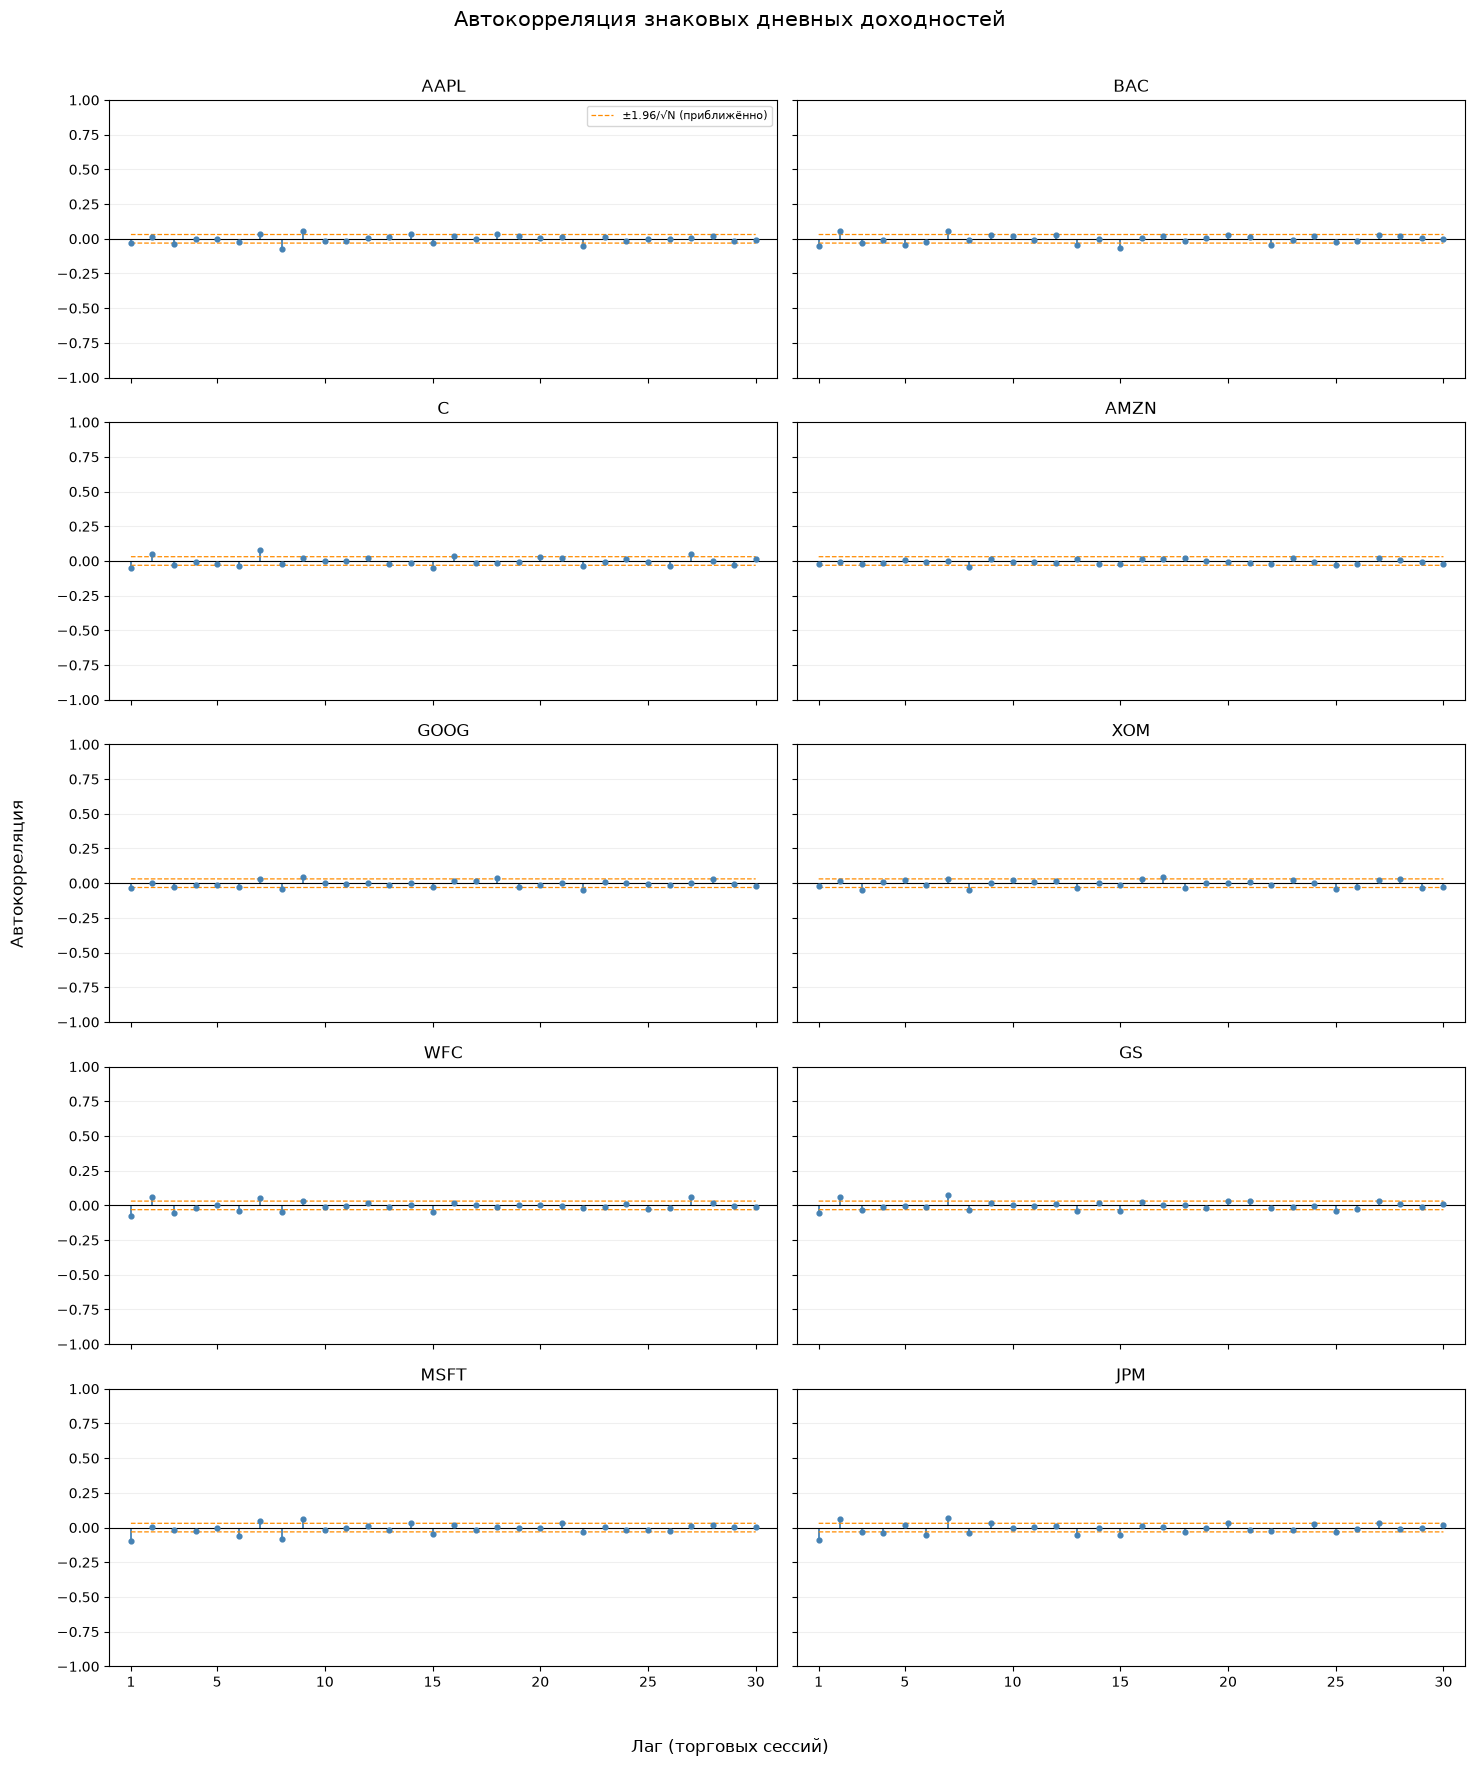

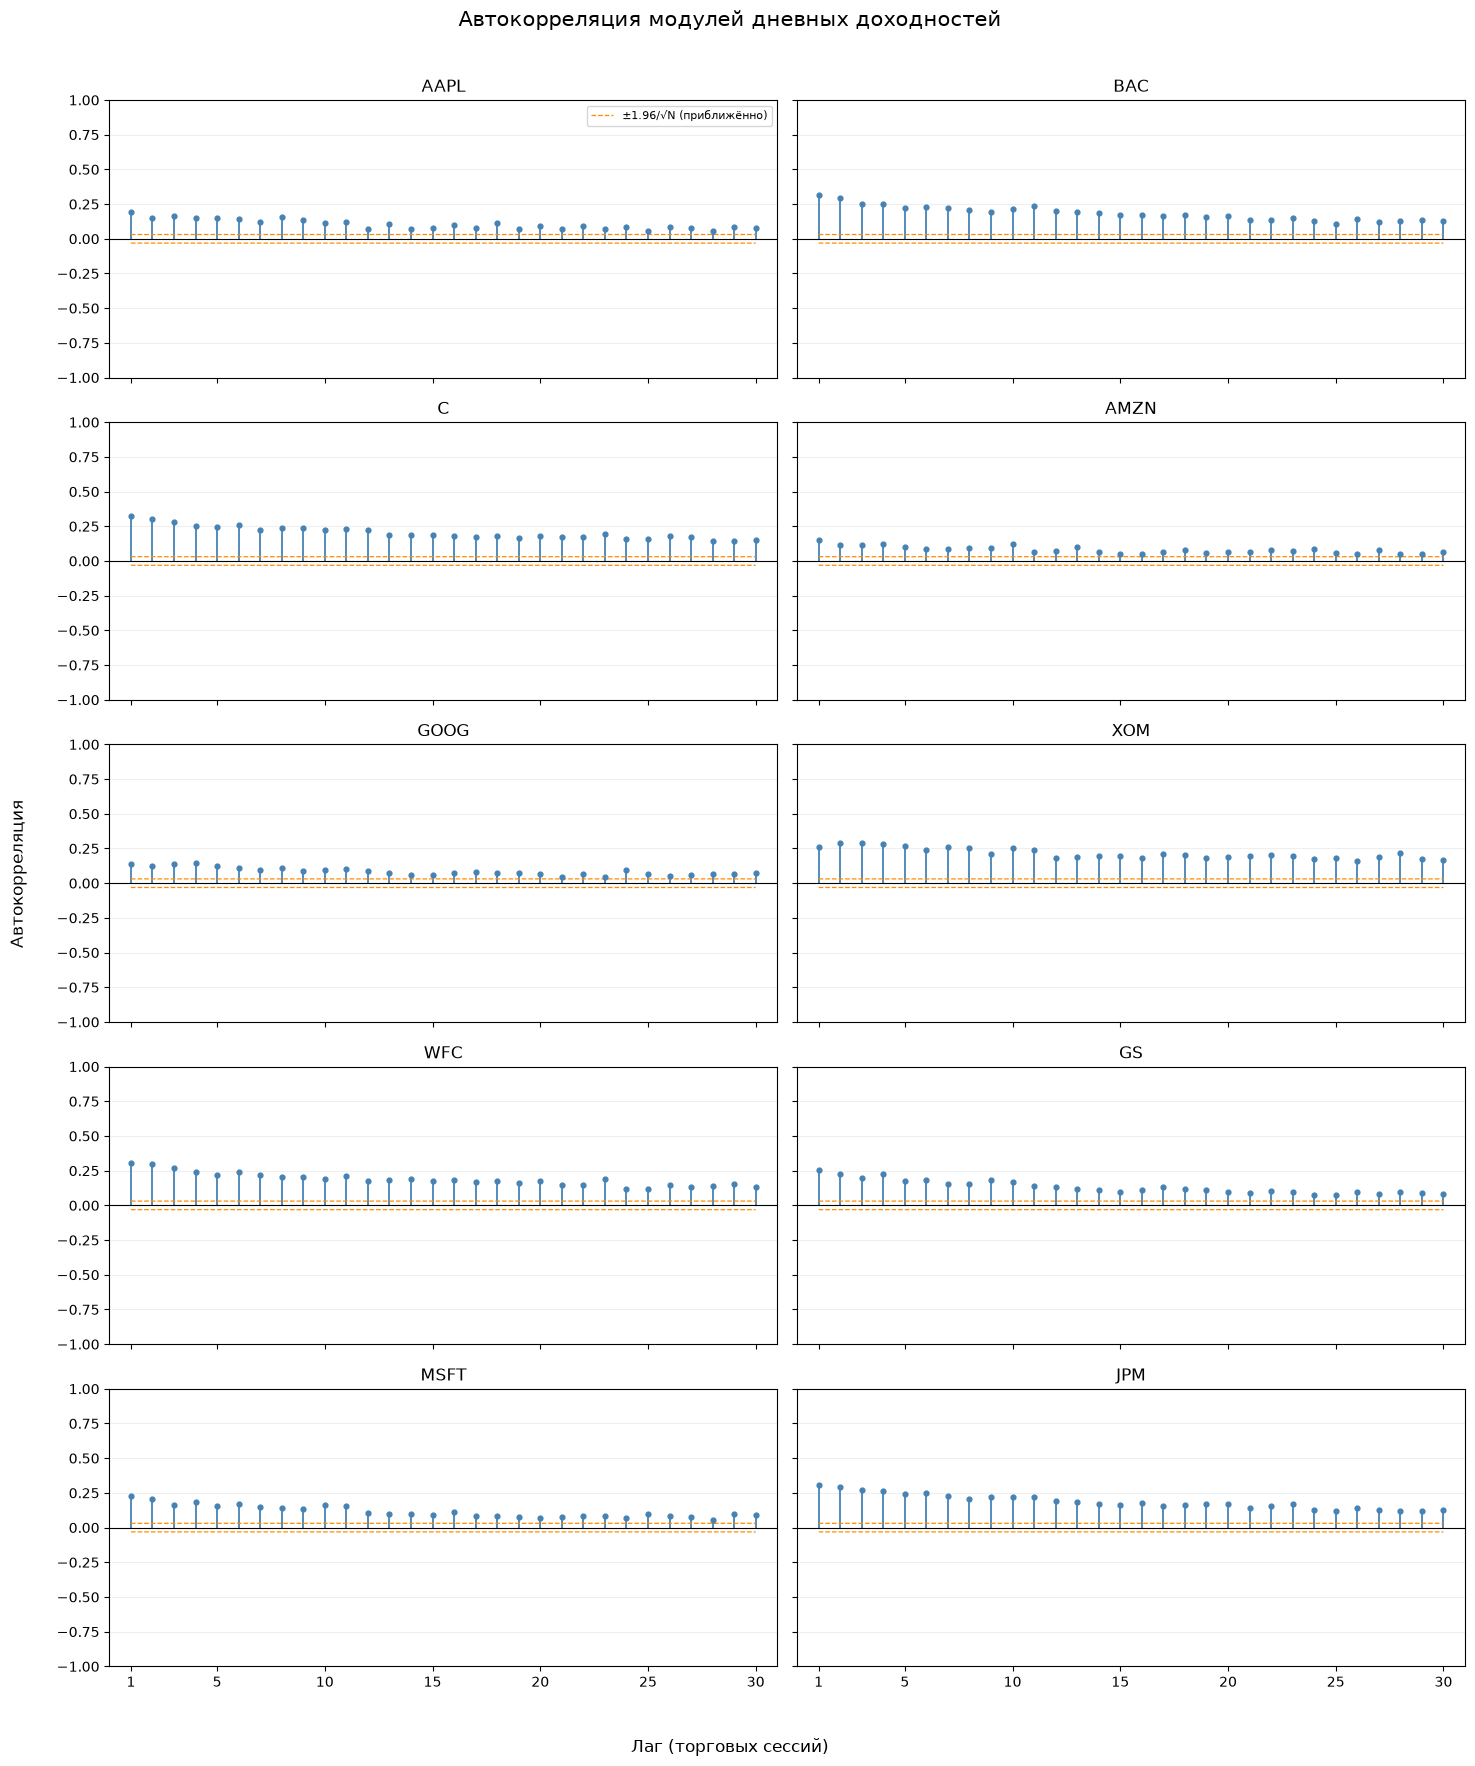

In [ ]:
def plot_acf_grid(results, title):
    fig, axes = plt.subplots(5, 2, figsize=(15, 18), sharex=True, sharey=True)
    for ax, ticker in zip(axes.flat, top_tickers):
        summary = results[ticker]
        lags = summary.index.to_numpy(dtype=int)
        values = summary["Автокорреляция"].to_numpy(dtype=float)
        ns = summary["Число пар N"].to_numpy(dtype=float)
        bounds = 1.96 / np.sqrt(ns)
        ax.vlines(lags, 0, values, color="steelblue", linewidth=1.3)
        ax.scatter(lags, values, color="steelblue", s=12, zorder=3)
        ax.plot(lags, bounds, color="darkorange", linestyle="--", linewidth=0.9, label="±1.96/√N (приближённо)")
        ax.plot(lags, -bounds, color="darkorange", linestyle="--", linewidth=0.9)
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(ticker)
        ax.set_ylim(-1, 1)
        ax.set_xlim(0, 31)
        ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
        ax.grid(axis="y", alpha=0.2)
    axes[0, 0].legend(loc="upper right", fontsize=8)
    fig.suptitle(title, fontsize=15)
    fig.supxlabel("Лаг (торговых сессий)")
    fig.supylabel("Автокорреляция")
    fig.tight_layout(rect=[0.02, 0.02, 1, 0.97])
    plt.show()


plot_acf_grid(acf_returns, "Автокорреляция знаковых дневных доходностей")
plot_acf_grid(acf_abs_returns, "Автокорреляция модулей дневных доходностей")

# 6. Анализ временных рядов (сырые данные)

## 6.1. Нестационарность цен

Давайте изучим статистические свойства Close для выбранных акций на примере AAPL. Сперва посмотрим на график:

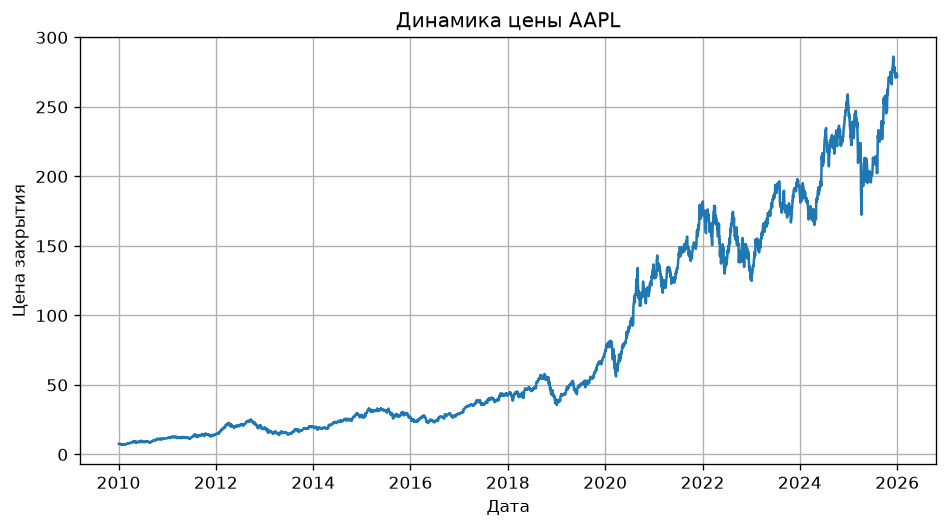

In [17]:
aapl_close = ohlcv_top_not_adj.Close.AAPL

plt.figure(dpi=120, figsize=(8, 4.5))
plt.plot(aapl_close)
plt.xlabel("Дата")
plt.ylabel("Цена закрытия")
plt.title("Динамика цены AAPL")
plt.grid()
plt.tight_layout()
plt.show()

Очевидно, временной ряд не стационарен – есть достаточно стабильный тренд вверх, и дисперсия однозначно не постоянна. Это подтверждают графики ACF и PACF:

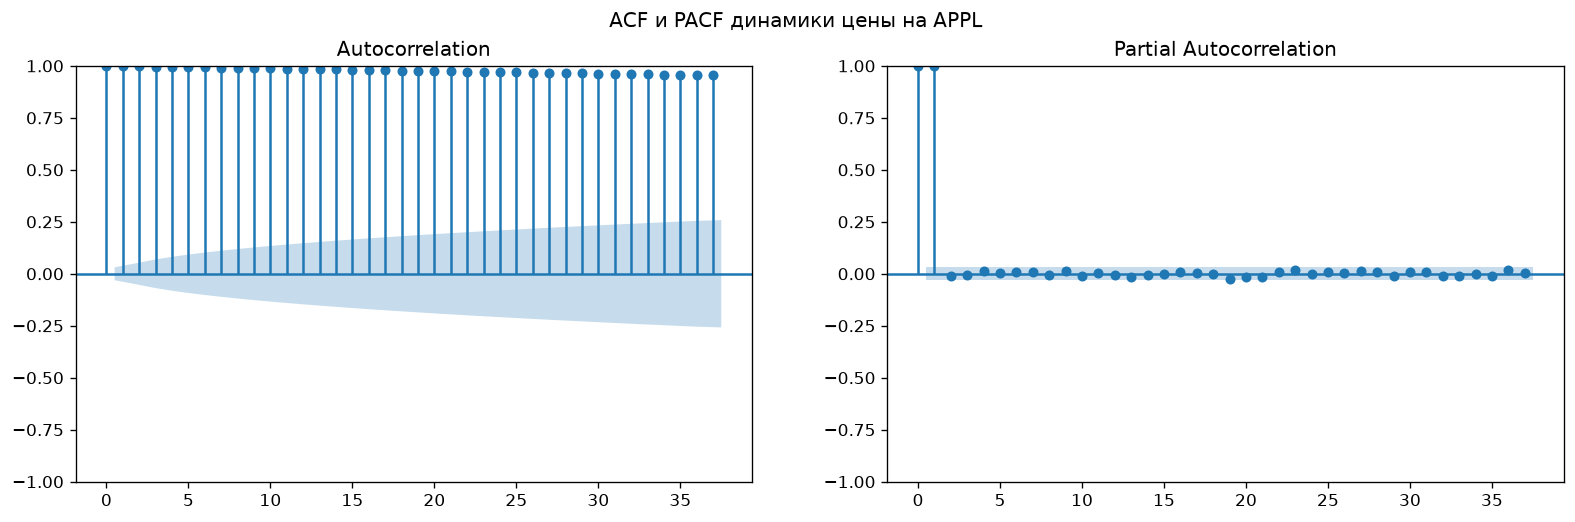

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, dpi=120, figsize=(16, 4.5))

plot_acf(aapl_close, ax=ax1)
plot_pacf(aapl_close, ax=ax2)
plt.suptitle("ACF и PACF динамики цены на APPL")
plt.show()

Именно такое поведение мы видим в случае нестационарных процессов – автокорреляция затухает медленно, а частичная автокорреляция примерно 1 на лаге 1 и около 0 далее. Так происходит потому, что нестационарный процесс ведёт себя как AR(1) с кэффициентом около 1.

Можем убедиться в нестационарности с помощью Augmented Dickey-Fuller теста. Его нулевая гипотеза – наличие unit root (нестационарность), альтернативная – отсутствие (стационарность). Предполагая возможное наличие линейного тренда, выберем тип регрессии `"ct"`. Тогда наша альтернативная гипотеза меняется на тренд-стационарность.

In [19]:
ADF(aapl_close, trend="ct")

Test Statistic,-1.218
P-value,0.907
Lags,18


Значит, тест указывает на нестационарность данных, как и ожидалось. Проверим на стационарность все акции в выборке:

In [20]:
print("ADF тест на стационарность цен")
print("Тикер:\tP-value (H0: нестационарность)")
for ticker in top_tickers:
    print(f"{ticker}:\t{ADF(ohlcv_top_not_adj.Close[ticker], trend="ct").pvalue:.4f}")

ADF тест на стационарность цен
Тикер:	P-value (H0: нестационарность)
AAPL:	0.9068
BAC:	0.2330
C:	0.7443
AMZN:	0.5170
GOOG:	1.0000
XOM:	0.6506
WFC:	0.8975
GS:	1.0000
MSFT:	0.7978
JPM:	0.9939


Значит, все временные ряды оценены как нестационарные. Это соответствует финансовой теории – цены на акции часто моделируется как случайное блуждание, то есть именно интегрированный (нестационарный) процесс.

Всё-таки, ADF неидеален, так как не учитывает, например, структурные сдвиги и может интерпретировать их как unit root, поэтому в идеале дальнейший анализ должен это учитывать.

## 6.2. Стационарность доходности

Для будущей корректной работы модели мы хотим стремиться к стационарности данных. Один вариант, как мы можем это сделать, этой перейти к доходности. Посмотрим на график процентного изменения цены:

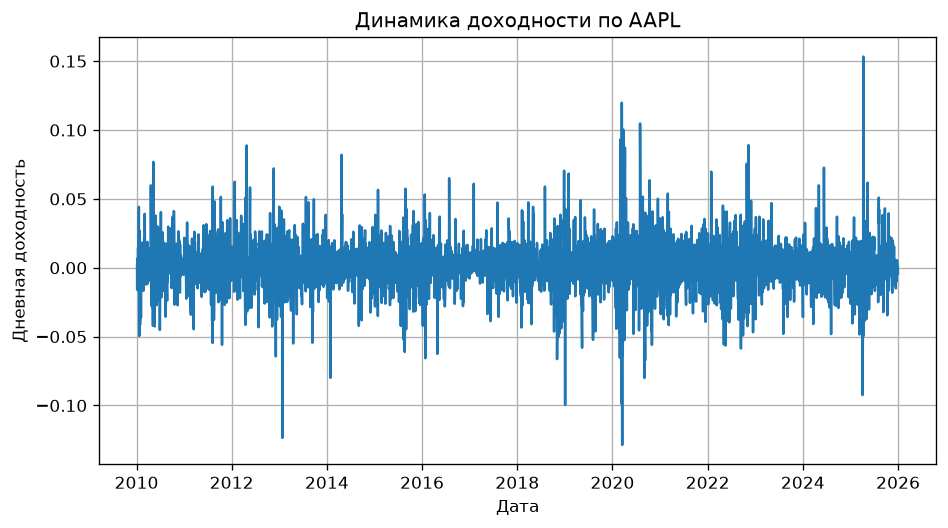

In [21]:
aapl_returns_daily = aapl_close.pct_change()[1:]

plt.figure(dpi=120, figsize=(8, 4.5))
plt.plot(aapl_returns_daily)
plt.xlabel("Дата")
plt.ylabel("Дневная доходность")
plt.title("Динамика доходности по AAPL")
plt.grid()
plt.tight_layout()
plt.show()

Это классический график: доходность выглядит почти полностью как шум с непостоянной дисперсией (гетероскедастичностью).

Заметим, что мы берём процентное изменение без учёта пропуска нерабочих дней – это стандартная практика.

Давайте проверим, что переход к доходности и правда убрал нестационарность:

In [22]:
print("ADF тест на стационарность доходности")
print("Тикер:\tP-value (H0: нестационарность)")
for ticker in top_tickers:
    print(f"{ticker}:\t{ADF(ohlcv_top_not_adj.Close[ticker].pct_change()[1:], trend="ct").pvalue:.4f}")

ADF тест на стационарность доходности
Тикер:	P-value (H0: нестационарность)
AAPL:	0.0000
BAC:	0.0000
C:	0.0000
AMZN:	0.0000
GOOG:	0.0000
XOM:	0.0000
WFC:	0.0000
GS:	0.0000
MSFT:	0.0000
JPM:	0.0000


Итак, переход к доходности и правда даёт нам стационарность.

## 6.3. Гетероскедастичность доходности

Посмотрим на ACF и PACF – они обычно позволяюьт нам понять какую модель стоит взять для нашей задачи:

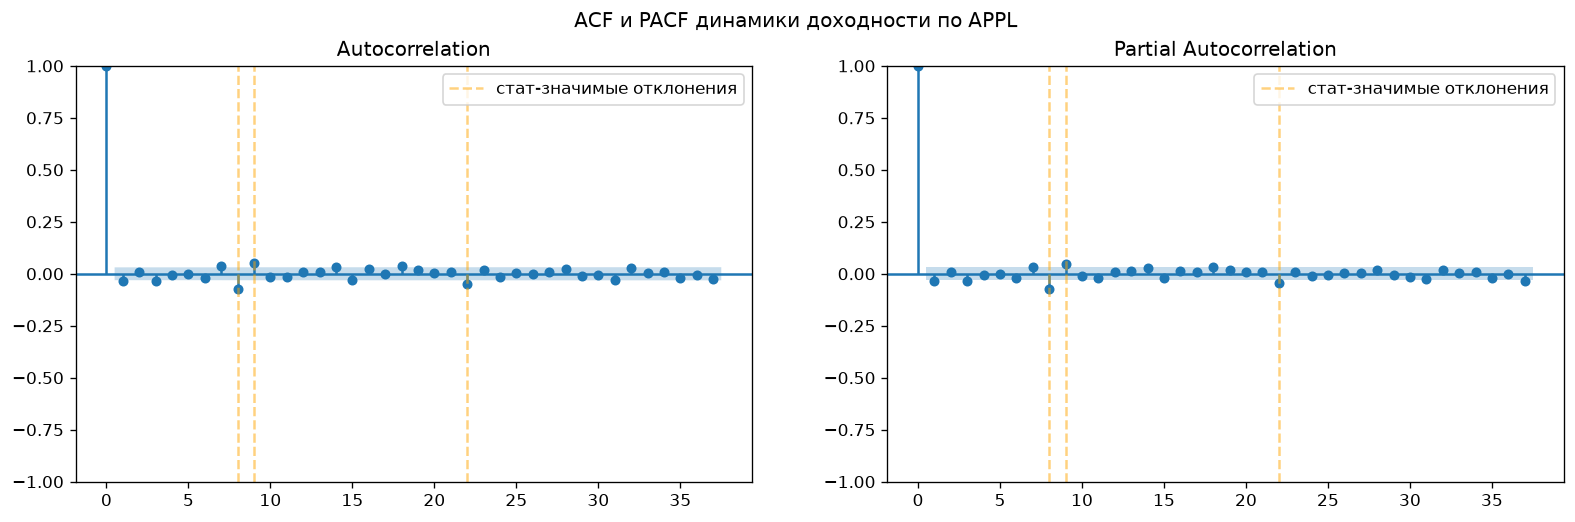

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, dpi=120, figsize=(16, 4.5))

plot_acf(aapl_returns_daily, ax=ax1)
ax1.vlines([8, 9, 22], -1, 1, color="orange", linestyles="--", alpha=0.5, label="стат-значимые отклонения")
ax1.legend()

plot_pacf(aapl_returns_daily, ax=ax2)
ax2.vlines([8, 9, 22], -1, 1, color="orange", linestyles="--", alpha=0.5, label="стат-значимые отклонения")
ax2.legend()

plt.suptitle("ACF и PACF динамики доходности по APPL")
plt.show()

Мы можем заметить небольшие отклонения от доверительного интервала для лагов 8, 9 и 22 по ACF и PACF. Но они лишь небольшие и скорее всего незначительны, а отклонение – результат множественного сравнения. Дополнительные статистические тесты (более робастные, чем Ljung-Box) могут это проверить.

Но вновь финансовая теория подсказывает, что всё выглядит именно так, как ожидается: простой автокорреляции практически нет, зато стоит ожидать значительной гетероскедастичности. Один вариант её продемонстрировать: посмотреть на ACF и PACF квадратов доходности.

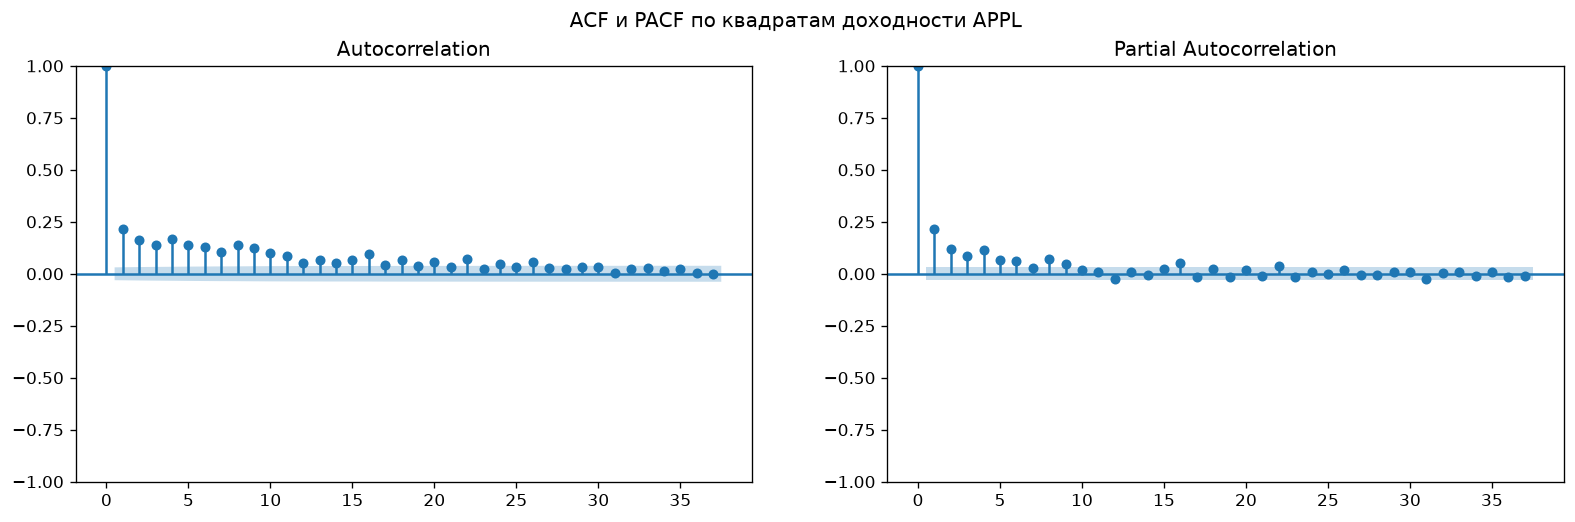

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, dpi=120, figsize=(16, 4.5))
plot_acf(aapl_returns_daily**2, ax=ax1)
plot_pacf(aapl_returns_daily**2, ax=ax2)
plt.suptitle("ACF и PACF по квадратам доходности APPL")
plt.show()

Как и ожидалось, мы видим автокорреляцию в квадратах доходности, то есть кластеризацию волатильности. Можем проверить это и через LM тест:

In [25]:
print("LM тест на гетероскедастичность доходности")
print("Тикер:\tP-value (H0: нулевые коэф. ARCH)")
for ticker in top_tickers:
    print(f"{ticker}:\t{het_arch(ohlcv_top_not_adj.Close[ticker].pct_change()[1:], result_object=True).lmpval:.4f}")

LM тест на гетероскедастичность доходности
Тикер:	P-value (H0: нулевые коэф. ARCH)
AAPL:	0.0000
BAC:	0.0000
C:	0.0000
AMZN:	0.0000
GOOG:	0.0000
XOM:	0.0000
WFC:	0.0000
GS:	0.0000
MSFT:	0.0000
JPM:	0.0000


Тест подтверждает гетероскедастичность и указывает на валидность применения ARCH/GARCH для исследования динамики доходности.

## 6.4. Вывод

Основные результаты этой части анализа:
- Динамика цен нестационарна, и требует трансформации данных для стационарности. В частности это означает, что задача предсказания цены напрямую **проблематична**, так как большинство моделей предполагает стационарные распределения к которым мы делаем `fit`. Тем самым, выбор таргета стоит делать в пользу стационарных величин.
- Динамика доходности стационарна. Это можно считать одним из наиболее сильных аргументов в пользу предсказания доходности, нежели чем самих цен, что мы и планируем делать на дальнейших этапах.
- Динамика доходности гетероскедастична. Кроме того, что тем самым модели вроде ARCH и GARCH можно рассматривать как одни из ключевых для дальнейшего анализа, это также значит, что без прямой автокорреляции мы всё равно имеем межвременные зависимости в данных, вроде кластеризации волатильности, из-за чего подходы в виде K-fold CV будут создавать bias в нашем анализе.

Также стоит отметить возможность структурных сдвигов, которые уже обычно тестируются при наличии обученной модели. Это указывает на важность оценки устойчивости модели и её динамической калибровки в дальнейшем анализе. Отдельным вопросом также остаётся кросс-секционная взаимосвязь между рядами и её анализ.

## *Более расширенный анализ стационарности adjusted рядов (которые имеют значительно другие свойства), а также анализ динамики волатильности, выполнены в отдельном ноутбуке `stationarity_volatility_eda`.*